In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
%matplotlib inline

In [2]:
url ="https://api.covid19india.org/csv/latest/case_time_series.csv"
df = pd.read_csv(url)
df.head()
from datetime import datetime
#df.Date = pd.to_datetime(df.Date, format = "%d %B %Y")
df.set_index("Date_YMD", inplace = True)
df = df.drop(["Date","Daily Confirmed","Daily Recovered", "Daily Deceased","Total Deceased"], axis=1)
df.tail(5)

,Total Confirmed,Total Recovered
Date_YMD,,
2021-10-27,34231030,33606620
2021-10-28,34245337,33619809
2021-10-29,34259552,33633358
2021-10-30,34272492,33648030
2021-10-31,34285399,33661182


In [3]:
df_test = df['2020–06–01':]
df_train = df['2020–01–30': '2021–05–30']

In [4]:
generator_train = TimeseriesGenerator(df_train["Total Confirmed"], df_train["Total Confirmed"], length=5, batch_size=1)
generator_test = TimeseriesGenerator(df_test["Total Confirmed"], df_test["Total Confirmed"], length=5, batch_size=1)

In [5]:
tf.random.set_seed(13)
model_1 = tf.keras.Sequential([
tf.keras.layers.Dense(64, activation='relu',input_dim=5),
tf.keras.layers.Dense(64, activation='relu'),
tf.keras.layers.Dense(1)
])

In [6]:
model_1.summary()
model_1.compile(optimizer ='adam', loss='mse', metrics = 'mae')

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 64)                384       
                                                                 
 dense_1 (Dense)             (None, 64)                4160      
                                                                 
 dense_2 (Dense)             (None, 1)                 65        
                                                                 
Total params: 4,609
Trainable params: 4,609
Non-trainable params: 0
_________________________________________________________________


Epoch 1/360
299/299 [==============================] - 2s 5ms/step - loss: 6462675877888.0000 - mae: 832955.1250 - val_loss: 298144890880.0000 - val_mae: 482776.4062
Epoch 2/360
299/299 [==============================] - 1s 3ms/step - loss: 166813908992.0000 - mae: 285995.8125 - val_loss: 117912043520.0000 - val_mae: 204957.1875
Epoch 3/360
299/299 [==============================] - 1s 3ms/step - loss: 217667239936.0000 - mae: 334961.7188 - val_loss: 319300796416.0000 - val_mae: 468353.4062
Epoch 4/360
299/299 [==============================] - 1s 4ms/step - loss: 174100824064.0000 - mae: 310477.9688 - val_loss: 285929701376.0000 - val_mae: 472610.1250
Epoch 5/360
299/299 [==============================] - 1s 4ms/step - loss: 216504369152.0000 - mae: 332116.4375 - val_loss: 107369054208.0000 - val_mae: 172325.7812
Epoch 6/360
299/299 [==============================] - 1s 4ms/step - loss: 187387215872.0000 - mae: 302572.9062 - val_loss: 121836789760.0000 - val_mae: 197621.6719
Epoch 7/3

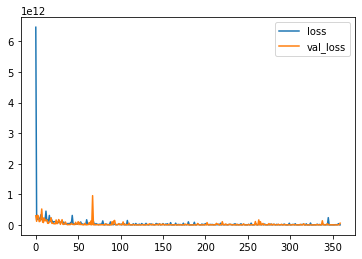

In [7]:
history = model_1.fit(generator_train, epochs = 360, validation_data = generator_test)
history.history
result = pd.DataFrame(history.history)
result.head(10)
result[["loss", "val_loss"]].plot()

In [9]:
df_predict = model_1.predict(generator_test)
df_predict = tf.squeeze(df_predict)
df_predict.numpy().shape
df_predict_df = pd.DataFrame(df_predict, columns = ["Next_Day_Pred"])
df_predict_df



,Next_Day_Pred
0,10489629.0
1,10509088.0
2,10529518.0
3,10549686.0
4,10568193.0
...,...
294,34554732.0
295,34568504.0
296,34584156.0
297,34600424.0


In [ ]:
df_test[6:].tail()

,Total Confirmed,Total Recovered,Total Deceased
Date_YMD,,,
2021-10-27,34231030,33606620,455828
2021-10-28,34245337,33619809,456633
2021-10-29,34259552,33633358,457184
2021-10-30,34272492,33648030,457629
2021-10-31,34285399,33661182,457880


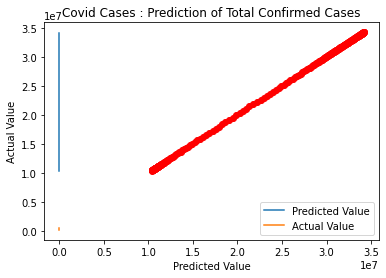

In [ ]:
plt.scatter(df_predict,df_test['Total Confirmed'][5:], color="red")
plt.xlabel("Predicted Value")
plt.ylabel("Actual Value")
plt.title("Covid Cases : Prediction of Total Confirmed Cases")
plt.plot(df_predict, label="Predicted Value")
plt.plot(df_test['Total Deceased'][5:].values, label="Actual Value")
plt.legend();

In [ ]:
Result_df=df_test[5:]
df_predict_df

,Next_Day_Pred
0,10360278.0
1,10379505.0
2,10399716.0
3,10419685.0
4,10437917.0
...,...
294,34127260.0
295,34140820.0
296,34156316.0
297,34172436.0


In [ ]:
df_predict_df['Date'] = pd.date_range(start="2021–05–06", periods=len(df_predict_df), freq="D")
df_predict_df.Date = pd.to_datetime(df_predict_df.Date, format = "%d %B %Y")
df_predict_df.set_index("Date", inplace = True)
pd.concat([Result_df, df_predict_df], axis=1)

ValueError: ignored